In [1]:
import sys; sys.path.insert(0, "../src")
%load_ext autoreload
%autoreload 2
import numpy as np
from sfftradar.radial import load_seq, frame_cube, SEQS
from sfftradar.rd import W_RANGE, W_DOPPLER
from sfftradar.sfft import flat_window, sparse_fft_mc, sparse_ops, dense_ops

N = 256
WS = {B: flat_window(N, B)[0] for B in (16, 32, 64)}


def row_inputs(seq, n):
    """Doppler inputs of one frame: (512 rows, 256 chirps, 16 channels), windowed, after the range FFT."""
    cube = frame_cube(seq, n)
    cube = cube - cube.mean(axis=(0, 1), keepdims=True)
    return np.fft.fft(cube * W_RANGE[:, None, None], axis=0) * W_DOPPLER[None, :, None]


def dense_peaks(Pr, thr):
    """Local maxima of one row's dense power that are above thr."""
    return [f for f in range(N) if Pr[f] > thr and Pr[f] >= Pr[(f - 1) % N] and Pr[f] >= Pr[(f + 1) % N]]

In [2]:
STEP = 25
res = {}
rng = np.random.default_rng(0)
for tag in SEQS:
    seq = load_seq(tag)
    for B, w in WS.items():
        hit = tot = 0; cost = 0.0; nrows = 0; busy = 0
        for n in seq.frames[::STEP]:
            din = row_inputs(seq, n)
            P = np.sum(np.abs(np.fft.fft(din, axis=1)) ** 2, axis=2)     # dense power, for checking
            med = np.median(P, axis=1)
            for r in range(512):
                thr = med[r] * 10                                         # 10 dB, as in Phase 2
                pk = dense_peaks(P[r], thr)
                st = {}
                est = sparse_fft_mc(din[r], B, w, rng=rng, stats=st)
                Ps = np.zeros(N)
                for f, v in est.items():
                    Ps[f] = np.sum(np.abs(v) ** 2)
                got = Ps > thr
                hit += sum(got[(f - 1) % N] or got[f] or got[(f + 1) % N] for f in pk)
                tot += len(pk)
                cost += sparse_ops(N, B, w, st["rounds"])
                nrows += 1
                busy += len(pk) > 0
        res[(tag, B)] = (hit / tot, cost / nrows / dense_ops(N), busy / nrows)
        print(f"{tag:12s} B={B:2d}  peaks kept {hit/tot:.2f}  cost vs dense {cost/nrows/dense_ops(N):.2f}  "
              f"skip-empty cost {busy/nrows:.2f}")

np.save("../results/phase3_real.npy", res)

city         B=16  peaks kept 0.03  cost vs dense 0.51  skip-empty cost 0.57
city         B=32  peaks kept 0.24  cost vs dense 1.29  skip-empty cost 0.57
city         B=64  peaks kept 0.61  cost vs dense 2.99  skip-empty cost 0.57
countryside  B=16  peaks kept 0.04  cost vs dense 0.46  skip-empty cost 0.40
countryside  B=32  peaks kept 0.27  cost vs dense 0.98  skip-empty cost 0.40
countryside  B=64  peaks kept 0.60  cost vs dense 2.12  skip-empty cost 0.40
highway      B=16  peaks kept 0.07  cost vs dense 0.46  skip-empty cost 0.28
highway      B=32  peaks kept 0.35  cost vs dense 0.85  skip-empty cost 0.28
highway      B=64  peaks kept 0.70  cost vs dense 1.70  skip-empty cost 0.28


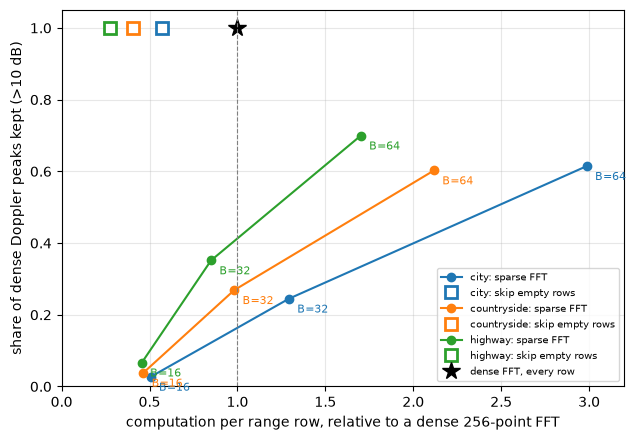

In [3]:
import matplotlib.pyplot as plt

res = np.load("../results/phase3_real.npy", allow_pickle=True).item()
colors = {"city": "C0", "countryside": "C1", "highway": "C2"}

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for tag, c in colors.items():
    pts = [res[(tag, B)] for B in (16, 32, 64)]
    xs = [p[1] for p in pts]
    ys = [p[0] for p in pts]
    ax.plot(xs, ys, "o-", color=c, label=f"{tag}: sparse FFT")
    for B, x, y in zip((16, 32, 64), xs, ys):
        ax.annotate(f"B={B}", (x, y), textcoords="offset points", xytext=(6, -10), fontsize=8, color=c)
    ax.plot(pts[0][2], 1.0, "s", color=c, markersize=8, markerfacecolor="white", markeredgewidth=2,
            label=f"{tag}: skip empty rows")

ax.plot(1.0, 1.0, "k*", markersize=13, label="dense FFT, every row")
ax.axvline(1.0, color="gray", lw=0.8, ls="--")
ax.set_xlabel("computation per range row, relative to a dense 256-point FFT")
ax.set_ylabel("share of dense Doppler peaks kept (>10 dB)")
ax.set_xlim(0, 3.2)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout()
plt.savefig("../figures/fig3_recall_vs_cost.png", dpi=150)
plt.show()

In [ ]:
STEP = 25
res_c = {}
for tag in SEQS:
    seq = load_seq(tag)
    frames = seq.frames[::STEP]
    for c in (2.0, 4.0, 8.0):
        for B, w in WS.items():
            rng = np.random.default_rng(0)
            hit = tot = 0; cost = 0.0; nrows = 0
            for n in frames:
                din = row_inputs(seq, n)
                P = np.sum(np.abs(np.fft.fft(din, axis=1)) ** 2, axis=2)
                med = np.median(P, axis=1)
                for r in range(0, 512, 4):                    # every 4th row, to keep it quick
                    thr = med[r] * 10
                    pk = dense_peaks(P[r], thr)
                    st = {}
                    est = sparse_fft_mc(din[r], B, w, c=c, rng=rng, stats=st)
                    Ps = np.zeros(N)
                    for f, v in est.items():
                        Ps[f] = np.sum(np.abs(v) ** 2)
                    got = Ps > thr
                    hit += sum(got[(f - 1) % N] or got[f] or got[(f + 1) % N] for f in pk)
                    tot += len(pk)
                    cost += sparse_ops(N, B, w, st["rounds"])
                    nrows += 1
            res_c[(tag, c, B)] = (hit / tot, cost / nrows / dense_ops(N))
            print(f"{tag:12s} c={c} B={B:2d}  kept {hit/tot:.2f}  cost {cost/nrows/dense_ops(N):.2f}")

np.save("../results/phase3_c_sweep.npy", res_c)

city         c=2.0 B=16  kept 0.30  cost 2.04
